# Benchmark: a gamma mean and a gamma shape

A gamma GLM gives every row the same shape, so the variance is a constant multiple of the squared mean. When the shape also depends on a covariate, that model estimates the mean correctly on average but uses the same shape for every row, and its predicted distributions are too wide for some rows and too narrow for others. This study asks whether `GammaLSS`, the gamma family whose mean and shape each have their own predictor, recovers both, compared with constant-shape gamma fits from mboostrs, statsmodels and scikit-learn.

Two tasks, four standard normal predictors. `noise` is unused. The variance is `mu**2 / shape`.

* **linear**: `log mu = 0.20 + 0.45 x1 - 0.30 x2` and `log shape = 1.15 + 0.85 x3`.
* **smooth**: `log mu = 0.10 + sin(1.6 x1) + 0.25 x2` and `log shape = 0.90 + 0.70 sin(2 x3)`.

Each fit sees 1,500 training rows and is scored on the same 4,000 test rows (one test sample per task, four training seeds). The boosting fits use step length (learning rate) `nu=0.1`, and 5-fold cross-validation chooses the stopping iteration `mstop` (the number of boosting steps) from every step of a path of 400 steps for a linear fit and 1,000 for an additive fit. The location-scale fits (`glmboostLSS`, `gamboostLSS`) give the mean and the shape each its own additive predictor. They use the non-cyclic algorithm: each step updates only one of the two, the mean or the shape, whichever update lowers the loss most, rather than updating both at every step. The stopping iteration is therefore one total count shared by the two parameters.

`GammaLSS.sigma` is the gamma shape, modelled on a log link; in R `gamlss` the gamma family's `sigma` is the coefficient of variation, `1/sqrt(shape)`. A statsmodels Gamma GLM reports `scale`, the Pearson dispersion `phi` (the mean squared Pearson residual), and its log-likelihood evaluates the gamma density at shape `1/phi`, so `scale` and shape are reciprocals. The maximum-likelihood estimate (MLE) of the shape, the value that maximises the gamma likelihood at the fitted means, is a different number. scikit-learn's `GammaRegressor(alpha=0)` predicts a mean and no shape; the constant shape scored for it here is the shape MLE at its predicted training means, the same quantity `GammaReg.nuisance()` returns for an mboostrs fit.

**Own negative log density** is the test mean negative log density of the fit's own predicted mean and shape, in nats per row; lower is better. **At the true shape** plugs the generating shape into every fit's predicted mean, so it compares means and does not reward the shape model.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the conditional distribution of a positive continuous response whose spread is not a constant multiple of the squared mean |
| **Observed response** | a simulated gamma draw |
| **Estimand** | test mean negative log density; absolute error of the mean and of log shape |
| **Units** | nats per row; the response's own units |
| **Sampling unit** | one row; 1,500 training and 4,000 test rows per seed |
| **Dependence** | independent rows |
| **Split / resampling unit** | one shared test sample per task; 5-fold cross-validation on the training rows chooses `mstop` |
| **Tuning** | `nu=0.1`; 400 steps for a linear model and 1,000 for an additive model; cross-validation evaluates every step |
| **Uncertainty** | means across four independently generated training samples, evaluated on one shared independent test sample per task; no sampling intervals are reported |
| **Claim type** | methodological comparison on simulated data |
| **Not claimed** | that a gamma is the right distribution for every positive response, or that these step counts are optimal on other designs |

:::


In [1]:
# Read the recorded runs; this page does not refit the models.
import json
from pathlib import Path

import altair as alt
import polars as pl

from bench_tables import table

bench = json.loads(Path("bench_gamma_lss.json").read_text())


In [2]:
# Preserve the recorded method and replication for each score.
rows = []
for record in bench["results"]:
    rows.append({
        "task": record["task"],
        "seed": record["seed"],
        "method": record["method"],
        "own_nll": record["own_nll"],
        "nll_true": record["nll_at_true_shape"],
        "mae": record["mae"],
        "mae_log_shape": record["mae_log_shape"],
        "shape": record["shape_mean"],
        "seconds": record["seconds"],
        "mstop": record.get("mstop"),
    })
raw = pl.DataFrame(rows)


In [3]:
# Average the recorded scores within each task and method.
summary = (
    raw.group_by("task", "method")
    .agg(
        pl.col("own_nll").mean(),
        pl.col("nll_true").mean(),
        pl.col("mae").mean(),
        pl.col("mae_log_shape").mean(),
        pl.col("shape").mean(),
        pl.col("seconds").mean(),
        pl.col("mstop").mean(),
    )
    .sort("task", "own_nll")
)


In [4]:
# Retrieve recorded scores and convergence evidence for the interpretation.
def value(task, method, column):
    hit = summary.filter((pl.col("task") == task) & (pl.col("method") == method))
    return float(hit[column][0])


def seed_value(task, method, seed, column):
    hit = raw.filter(
        (pl.col("task") == task) & (pl.col("method") == method) & (pl.col("seed") == seed)
    )
    return float(hit[column][0])


def probe(label):
    return next(item for item in bench["usability"]["probes"] if item["label"] == label)


def n_at_cap(task, method):
    return sum(
        1
        for record in bench["results"]
        if record["task"] == task and record["method"] == method and record.get("at_boundary")
    )


In [5]:
scored = summary.filter(pl.col("method") != "generating Gamma")
table(
    scored.select("task", "method", "own_nll", "nll_true", "mae", "mae_log_shape", "shape", "seconds"),
    title="Gamma mean and shape",
    subtitle="Mean over 4 seeds; 1,500 training rows and 4,000 test rows",
    group="task",
    labels={
        "own_nll": "own NLL",
        "nll_true": "at true shape",
        "mae": "MAE",
        "mae_log_shape": "log-shape MAE",
        "shape": "mean shape",
        "seconds": "seconds",
    },
    better={"own_nll": "min", "mae": "min", "mae_log_shape": "min"},
    formats={"nll_true": 4, "shape": 2, "seconds": 3},
    notes=(
        "Own NLL is the test negative log density of the fit's own mean and shape, in nats per row. "
        "At true shape scores every predicted mean with the generating shape, so it compares means. "
        "Mean shape is GammaLSS sigma averaged over the test rows, GammaReg nuisance(), "
        "1 over the statsmodels Pearson scale, or the shape MLE at the sklearn predicted means. "
        "Lower is better. Bold marks the best scored value in each task.",
    ),
)

GT(_tbl_data=shape: (14, 8)
┌────────┬─────────────────┬──────────┬──────────┬──────────┬───────────────┬──────────┬───────────┐
│ task   ┆ method          ┆ own_nll  ┆ nll_true ┆ mae      ┆ mae_log_shape ┆ shape    ┆ seconds   │
│ ---    ┆ ---             ┆ ---      ┆ ---      ┆ ---      ┆ ---           ┆ ---      ┆ ---       │
│ str    ┆ str             ┆ f64      ┆ f64      ┆ f64      ┆ f64           ┆ f64      ┆ f64       │
╞════════╪═════════════════╪══════════╪══════════╪══════════╪═══════════════╪══════════╪═══════════╡
│ linear ┆ mboostrs        ┆ 0.85583  ┆ 0.854539 ┆ 0.034127 ┆ 0.054442      ┆ 4.238116 ┆ 1.511296  │
│        ┆ glmboostLSS     ┆          ┆          ┆          ┆               ┆          ┆           │
│        ┆ GammaLSS        ┆          ┆          ┆          ┆               ┆          ┆           │
│ linear ┆ mboostrs        ┆ 0.856857 ┆ 0.854757 ┆ 0.037101 ┆ 0.064167      ┆ 4.061657 ┆ 12.455158 │
│        ┆ gamboostLSS     ┆          ┆          ┆          ┆               ┆          ┆           │
│        ┆ GammaLSS        ┆          ┆          ┆          ┆               ┆          ┆           │
│ linear ┆ mboostrs        ┆ 1.05568  ┆ 0.855078 ┆ 0.043472 ┆ 0.759148      ┆ 2.089556 ┆ 0.061638  │
│        ┆ glmboost        ┆          ┆          ┆          ┆               ┆          ┆           │
│        ┆ GammaReg        ┆          ┆          ┆          ┆               ┆          ┆           │
│ linear ┆ sklearn         ┆ 1.055912 ┆ 0.855715 ┆ 0.048449 ┆ 0.759034      ┆ 2.090163 ┆ 0.002727  │
│        ┆ GammaRegressor  ┆          ┆          ┆          ┆               ┆          ┆           │
│ linear ┆ mboostrs        ┆ 1.0562   ┆ 0.855118 ┆ 0.058675 ┆ 0.756503      ┆ 2.104649 ┆ 0.316719  │
│        ┆ gamboost        ┆          ┆          ┆          ┆               ┆          ┆           │
│        ┆ GammaReg        ┆          ┆          ┆          ┆               ┆          ┆           │
│ …      ┆ …               ┆ …        ┆ …        ┆ …        ┆ …             ┆ …        ┆ …         │
│ smooth ┆ statsmodels     ┆ 0.986487 ┆ 0.924275 ┆ 0.063944 ┆ 0.451469      ┆ 2.220052 ┆ 0.01674   │
│        ┆ Gamma GLM       ┆          ┆          ┆          ┆               ┆          ┆           │
│        ┆ spline          ┆          ┆          ┆          ┆               ┆          ┆           │
│ smooth ┆ mboostrs        ┆ 1.232074 ┆ 1.324791 ┆ 0.588309 ┆ 0.622535      ┆ 1.379342 ┆ 3.001778  │
│        ┆ glmboostLSS     ┆          ┆          ┆          ┆               ┆          ┆           │
│        ┆ GammaLSS        ┆          ┆          ┆          ┆               ┆          ┆           │
│ smooth ┆ sklearn         ┆ 1.239452 ┆ 1.325642 ┆ 0.59563  ┆ 0.615052      ┆ 1.365101 ┆ 0.002393  │
│        ┆ GammaRegressor  ┆          ┆          ┆          ┆               ┆          ┆           │
│ smooth ┆ mboostrs        ┆ 1.240371 ┆ 1.327963 ┆ 0.600415 ┆ 0.615637      ┆ 1.363921 ┆ 0.103776  │
│        ┆ glmboost        ┆          ┆          ┆          ┆               ┆          ┆           │
│        ┆ GammaReg        ┆          ┆          ┆          ┆               ┆          ┆           │
│ smooth ┆ statsmodels     ┆ 1.286627 ┆ 1.325645 ┆ 0.59564  ┆ 0.956998      ┆ 0.951276 ┆ 0.008695  │
│        ┆ Gamma GLM       ┆          ┆          ┆          ┆               ┆          ┆           │
└────────┴─────────────────┴──────────┴──────────┴──────────┴───────────────┴──────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x109ab0170>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.row_group: 3>, column_label='task', column_align='left', column_width=None, stub_level=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='own_nll', type=<ColInfoTypeEnum.default: 1>, column_label='own NLL', column_align='right', column_width=None, stub_level=None), ColInfo(var='nll_true', type=<ColInfoTypeEnum.defaul

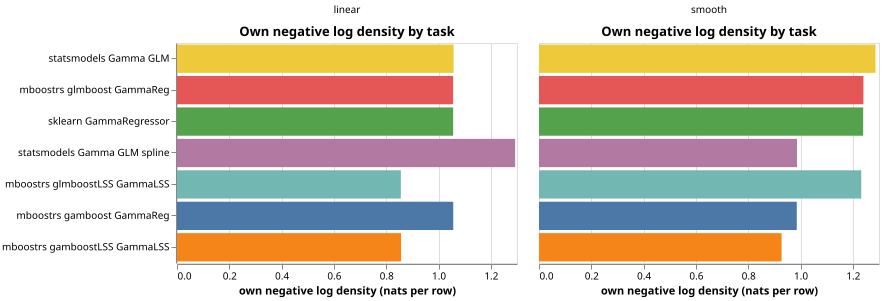

In [6]:
chart_rows = summary.filter(pl.col("method") != "generating Gamma")
alt.Chart(chart_rows).mark_bar().encode(
    x=alt.X("own_nll:Q", title="own negative log density (nats per row)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=340,
    height=220,
    title="Own negative log density by task",
).facet(column=alt.Column("task:N", title=None))

(the-linear-mean-with-a-shape-that-moves)=
## Linear mean and varying shape

`glmboostLSS` with `GammaLSS` matches the generating density. Mean own negative log density is {eval}`f"{value('linear', 'mboostrs glmboostLSS GammaLSS', 'own_nll'):.4f}"` nats per row, against {eval}`f"{value('linear', 'generating Gamma', 'own_nll'):.4f}"` for the generating distribution. Mean absolute error of log shape is {eval}`f"{value('linear', 'mboostrs glmboostLSS GammaLSS', 'mae_log_shape'):.3f}"`. The mean shape on the test rows is {eval}`f"{value('linear', 'mboostrs glmboostLSS GammaLSS', 'shape'):.2f}"` against the generating {eval}`f"{value('linear', 'generating Gamma', 'shape'):.2f}"`. Cross-validation stopped inside the 400-step path on every seed (mean chosen step {eval}`f"{value('linear', 'mboostrs glmboostLSS GammaLSS', 'mstop'):.0f}"`). The fit takes about {eval}`f"{value('linear', 'mboostrs glmboostLSS GammaLSS', 'seconds'):.2f}"` seconds.

A constant-shape gamma fit uses one fitted shape for every row. `glmboost` with `GammaReg` scores {eval}`f"{value('linear', 'mboostrs glmboost GammaReg', 'own_nll'):.3f}"`. The statsmodels Gamma GLM scores {eval}`f"{value('linear', 'statsmodels Gamma GLM', 'own_nll'):.3f}"` and sklearn, with a shape MLE plugged in at its predicted means, scores {eval}`f"{value('linear', 'sklearn GammaRegressor', 'own_nll'):.3f}"`. Scored at the generating shape, those same means are {eval}`f"{value('linear', 'mboostrs glmboost GammaReg', 'nll_true'):.4f}"`, {eval}`f"{value('linear', 'statsmodels Gamma GLM', 'nll_true'):.4f}"` and {eval}`f"{value('linear', 'mboostrs glmboostLSS GammaLSS', 'nll_true'):.4f}"`. The gap of about {eval}`f"{value('linear', 'statsmodels Gamma GLM', 'own_nll') - value('linear', 'mboostrs glmboostLSS GammaLSS', 'own_nll'):.2f}"` nats per row is the shape model, not the mean. Log-shape error for the constant-shape fits is about {eval}`f"{value('linear', 'mboostrs glmboost GammaReg', 'mae_log_shape'):.2f}"`.

The B-spline Gamma GLM adds flexibility to a mean whose log is linear. Its four-seed own negative log density is {eval}`f"{value('linear', 'statsmodels Gamma GLM spline', 'own_nll'):.3f}"`, and seed 0 alone is {eval}`f"{seed_value('linear', 'statsmodels Gamma GLM spline', 0, 'own_nll'):.3f}"` against {eval}`f"{seed_value('linear', 'statsmodels Gamma GLM spline', 1, 'own_nll'):.3f}"` on seed 1. The spline can produce extreme tail means, which incur a large negative log density. Its shape remains constant across rows.


(the-smooth-mean-and-the-smooth-shape)=
## Smooth mean and shape

A linear gamma misses the sine in the mean. The statsmodels Gamma GLM scores {eval}`f"{value('smooth', 'statsmodels Gamma GLM', 'own_nll'):.3f}"` and `glmboost` with `GammaReg` scores {eval}`f"{value('smooth', 'mboostrs glmboost GammaReg', 'own_nll'):.3f}"`. Absolute error of the mean is about {eval}`f"{value('smooth', 'statsmodels Gamma GLM', 'mae'):.2f}"`. A linear `GammaLSS` does not repair that: {eval}`f"{value('smooth', 'mboostrs glmboostLSS GammaLSS', 'own_nll'):.3f}"`, absolute error {eval}`f"{value('smooth', 'mboostrs glmboostLSS GammaLSS', 'mae'):.2f}"`. The missed curve is absorbed into the shape, which falls to about {eval}`f"{value('smooth', 'mboostrs glmboostLSS GammaLSS', 'shape'):.2f}"` against the generating {eval}`f"{value('smooth', 'generating Gamma', 'shape'):.2f}"`.

`gamboost` with `GammaReg` and `bbs(x1) + bols(x2) + bbs(x3) + bols(noise)` recovers the mean and keeps one shape. Own negative log density: {eval}`f"{value('smooth', 'mboostrs gamboost GammaReg', 'own_nll'):.4f}"`, the B-spline Gamma GLM {eval}`f"{value('smooth', 'statsmodels Gamma GLM spline', 'own_nll'):.4f}"`. At the true shape both are {eval}`f"{value('smooth', 'mboostrs gamboost GammaReg', 'nll_true'):.4f}"` and {eval}`f"{value('smooth', 'statsmodels Gamma GLM spline', 'nll_true'):.4f}"`, next to the generating {eval}`f"{value('smooth', 'generating Gamma', 'own_nll'):.4f}"`. Log-shape error stays about {eval}`f"{value('smooth', 'mboostrs gamboost GammaReg', 'mae_log_shape'):.2f}"`.

`gamboostLSS` fits a smooth to the shape as well. Own negative log density: {eval}`f"{value('smooth', 'mboostrs gamboostLSS GammaLSS', 'own_nll'):.4f}"` against the generating {eval}`f"{value('smooth', 'generating Gamma', 'own_nll'):.4f}"`. Log-shape error is {eval}`f"{value('smooth', 'mboostrs gamboostLSS GammaLSS', 'mae_log_shape'):.3f}"` and the mean shape is {eval}`f"{value('smooth', 'mboostrs gamboostLSS GammaLSS', 'shape'):.2f}"`. The mean is no better than the constant-shape smooth (absolute error {eval}`f"{value('smooth', 'mboostrs gamboostLSS GammaLSS', 'mae'):.3f}"` against {eval}`f"{value('smooth', 'mboostrs gamboost GammaReg', 'mae'):.3f}"`); the extra {eval}`f"{value('smooth', 'mboostrs gamboost GammaReg', 'own_nll') - value('smooth', 'mboostrs gamboostLSS GammaLSS', 'own_nll'):.3f}"` nats per row is the shape. The fit takes about {eval}`f"{value('smooth', 'mboostrs gamboostLSS GammaLSS', 'seconds'):.1f}"` seconds against a few hundredths for the spline GLM.

{eval}`f"{n_at_cap('smooth', 'mboostrs gamboostLSS GammaLSS')}"` of the four additive location-scale paths was still at the 1,000-step cap. That path may be underfit; that seed's own negative log density was {eval}`f"{seed_value('smooth', 'mboostrs gamboostLSS GammaLSS', 1, 'own_nll'):.4f}"`, already better than the spline GLM on the same seed ({eval}`f"{seed_value('smooth', 'statsmodels Gamma GLM spline', 1, 'own_nll'):.4f}"`). The other three paths stopped inside the grid.


## Prediction and parameter accessors

The calls below were run on the first linear training sample.

`predict` on a location-scale fit defaults to `type="link"`, which returns the log mean and the log shape. {eval}`probe("predict default is the log mean and the log shape")["detail"]` The benchmark uses `type="response"`, which returns the mean and the shape.

`logLik()` on a `GammaReg` fit returns the gamma log density at the fitted means and the `nuisance()` shape. The boosting loss omits the term `log(y)` of each row, which does not depend on the fit; `negative_risk()` returns minus that loss, and `logLik()` adds the omitted term back. On an 80-step path:

> {eval}`probe("GammaReg logLik is the density; negative_risk drops log y")["detail"]`

The cross-validated fit in the benchmark agrees. Seed 0 reports `logLik()` {eval}`f"{bench['recovery']['glmboost_loglik']:.6f}"` against the gamma density {eval}`f"{bench['recovery']['glmboost_scipy_loglik']:.6f}"` at shape {eval}`f"{bench['recovery']['glmboost_shape']:.4f}"`. `negative_risk()` is {eval}`f"{bench['recovery']['glmboost_negative_risk']:.6f}"`.

statsmodels' `scale` on the same rows is {eval}`f"{bench['recovery']['statsmodels_scale']:.4f}"`, so `1/scale` is {eval}`f"{bench['recovery']['statsmodels_shape']:.3f}"`, while the shape MLE is {eval}`f"{bench['recovery']['glmboost_shape']:.3f}"`. statsmodels' `llf` is the density at the Pearson dispersion. Using `1/nuisance()` as a statsmodels scale, or `1/scale` as a `GammaLSS` shape, mixes those two estimates.

On this sample the cross-validated `glmboost` path never selected `x3` or `noise`. `coef()` omits coefficients that are exactly zero, so neither appears in its output. `coef(off2int=True)` adds the offset, the constant from which boosting starts, to the intercept. The intercept is then {eval}`f"{bench['recovery']['glmboost_coef']['(Intercept)']:.3f}"`, `x1` is {eval}`f"{bench['recovery']['glmboost_coef']['x1']:.3f}"` and `x2` is {eval}`f"{bench['recovery']['glmboost_coef']['x2']:.3f}"`, against the statsmodels intercept {eval}`f"{bench['recovery']['statsmodels_params']['Intercept']:.3f}"`.

`autospec`, the automatic specification search, chooses `GammaReg` for this positive response when it is given no budget, and does not test whether the shape varies, because that test costs one distributional fit per fold:

> {eval}`probe("autospec without a budget")["detail"]`

With a budget for the family test, `autospec` fits `GammaLSS` on the same folds and compares its held-out negative log density with that of the constant-shape mean family it would otherwise choose; it adopts `GammaLSS` when the distributional family clearly wins. On this sample, where the shape depends on `x3`, `GammaLSS` wins. A search that adopts a distributional family stops at the family: the searches over shapes, pairs, residual trees and term removal apply to single-predictor models, and `rec.fit()` builds the distributional model:

> {eval}`probe("autospec with a family-probe budget")["detail"]`

`glmboost(family=GammaLSS())` raises a `TypeError` that names the functions to use:

> {eval}`probe("glmboost(family=GammaLSS())")["detail"]`

A non-positive response is refused: {eval}`probe("GammaReg rejects a non-positive response")["error"]`, {eval}`probe("GammaReg rejects a non-positive response")["detail"]`.

## Implications for the user

- When the spread of a positive response may depend on covariates, compare `GammaLSS` with a constant-shape gamma on held-out negative log density. Here the two give means of similar accuracy, and the gain of about 0.2 nats per row on the linear task and 0.06 on the smooth task comes from the shape model.
- A constant-shape gamma is adequate when only the mean is needed: on the at-true-shape score, which compares means only, `glmboost`/`gamboost` with `GammaReg`, the statsmodels linear GLM, sklearn and `GammaLSS` agree to within 0.002 nats per row whenever the mean model has the right form.
- A mis-specified mean is not repaired by a shape model: the linear `GammaLSS` on the smooth task absorbs the missed curve into a smaller shape. Fit the mean flexibly (`gamboostLSS`) before reading the shape.
- `GammaLSS` costs more time: about 1.5 seconds for the linear fit and 22 seconds for the additive one, against hundredths of a second for the GLMs.

## Limitations

- One generator per task, four training seeds and one test sample per task; no sampling intervals are reported.
- One of the four additive location-scale paths on the smooth task stopped at the 1,000-step cap, so that fit may be underfit; its score is included in the mean.
- R `gamboostLSS` is not among the methods compared.
- The results were measured with mboostrs 0.1.3.

## Reproduction

The tables read `bench_gamma_lss.json`; this page does not refit the models. The runner script that produced the file is not part of the public repository. The file records library versions, thread settings and the protocol in `provenance`. Timing standard deviations and standard errors describe variation across the training seeds; each method's elapsed time covers its own fit, tuning and prediction.